<center>
<h1>
<h1>APM 53674: ALTeGraD</h1>
<h2>Lab Session 1: Neural Machine Translation and Language Modeling</h2>
<h4>Lecture: Prof. Michalis Vazirgiannis<br>
Lab: Yang Zhang and Amr Mohamed</h4>
<h5>September 29, 2026</h5>
<br>
</center>

<hr style="border:10px solid gray"> </hr>
<p style="text-align: justify;">
This handout includes theoretical introductions, <font color='blue'>coding tasks</font> and <font color='red'>questions</font>. Before the deadline, you should submit <a href='https://forms.gle/9dyaes6dimfvyjwq6' target="_blank">here</a> a <B>.ipynb</B> file named <b>Lab1_Lastname_Firstname.ipynb</b> containing your notebook (with the gaps filled and your answers to the questions). Your answers should be well constructed and well justified. They should not repeat the question or generalities in the handout. When relevant, you are welcome to include figures, equations and tables derived from your own computations, theoretical proofs or qualitative explanations. One submission is required for each student. The deadline for this lab is <b>October 06
, 2026 11:59 PM</b>. No extension will be granted. Late policy is as follows: ]0, 24] hours late → -5 pts; ]24, 48] hours late → -10 pts; > 48 hours late → not graded (zero).
</p>
<hr style="border:5px solid gray"> </hr>


## <b>Neural Machine Translation</b></h2>

<h3><b>1. Learning Objective:</b></h2>
<p style="text-align: justify;">
In this lab, you will learn about sequence to sequence (seq2seq) architectures.
More precisely, we will implement the Neural Machine Translation (NMT) model described in <a href='https://arxiv.org/abs/1508.04025'>[Luong et al., 2015]</a> using Python 3.6 and PyTorch (the latest version).
The only difference is that we will be using non-stacked RNNs, whereas <a href='https://arxiv.org/abs/1508.04025'>[Luong et al., 2015]</a> uses stacked RNNs.

We will train our model on the task of English to French translation, using a set of sentence pairs from <a href='http://www.manythings.org/anki/'>http://www.manythings.org/anki/</a>, originally extracted from the Tatoeba project: <a href='https://tatoeba.org/eng/'>https://tatoeba.org/eng/</a>.

Our dataset features 136,521 pairs for training and 34,130 pairs for testing, which is quite small, but enough for the purpose of this lab.
The average size of a source sentence is 7.6 while the average size of a target sentence is 8.3.

$\underline{\textbf{Note}}$: the pairs have already been preprocessed.
Each sentence was turned into a list of integers starting from 4.
The integers correspond to indexes in the source and target vocabularies, that have been constructed from the training set, and in which the most frequent words have index 4.
0, 1, 2 and 3 are reserved respectively for the padding, out-of-vocabulary, start of sentence, and end of sentence special tokens.

<h3><b>2. Recurrent Neural Networks:</b></h3>
<p style="text-align: justify;">

While CNNs are good at dealing with grids, RNNs were specifically developed to be used with sequences.
As shown in Fig. 1, a RNN can be viewed as a chain of simple neural layers that share the same parameters.
From a high level, a RNN is fed an ordered list of input vectors $\big\{x_{1},...,x_{T}\big\}$ as well as an initial hidden state $h_{0}$ initialized to all zeros, and returns an ordered list of hidden states $\big\{h_{1},...,h_{T}\big\}$, as well as an ordered list of output vectors $\big\{y_{1},...,y_{T}\big\}$.
The hidden states may serve as input to the RNN units above in the case of a stacked architecture, or directly be used as they are (e.g., by the attention mechanism).
The hidden states correspond more or less to the "short-term" memory of the network.
<center>
<table><tr>
<td> <img src='https://1drv.ms/i/c/ae69638675180117/UQQXARh1hmNpIICuu4QBAAAAAMrZ9Edq70cBsjo?width=498&height=246' alt="Drawing" width= '500px'/> </td>
<td> <img src="https://1drv.ms/i/c/ae69638675180117/UQQXARh1hmNpIICuvIQBAAAAAJVN-1WBTh55QtY?width=1336&height=733" alt="Drawing" width='500px'/> </td>
</tr></table>

<b>Figure 1:</b> Left: 3 steps of an unrolled RNN (adapted from <a href='http://www.wildml.com/2015/09/recurrent-neural-networks-tutorial-part-2-implementing-a-language-model-rnn-with-python-numpy-and-theano/'>Denny Britz' blog</a>). Right: 3 steps of an unrolled stacked RNN.
The hidden states at a given position flow vertically through the RNN layers. On both sides, each circle represents a  RNN unit. </a><br>
</center>

<h3><b>3. Sequence-to-sequence architecture:</b></h3>
<p style="text-align: justify;">
Our input and output are sequences of words, respectively $x = \big(x_1, \dots ,x_{T_x}\big)$ and $y = \big(y_1, \dots ,y_{T_y}\big)$.
$x$ and $y$ are usually referred to as the $\textit{source}$ and $\textit{target}$ sentences.
<h4><b>3.1. Encoder</b></h4>
<p style="text-align: justify;">
Our encoder is a non-stacked unidirectional RNN with GRU units (see the appendix for details about the GRU.)



In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils import data
from torch.nn.utils.rnn import pad_sequence
from tqdm import tqdm
from nltk import word_tokenize
import sys
import json
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
import numpy as np
import matplotlib.pyplot as plt

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.



<b><h4><font color='blue'>
<hr style="border:10px solid blue"> </hr>
Task 1: </b><br>
Fill the gaps in the $\texttt{forward}$ function of the $\texttt{Encoder}$ class.
<hr style="border:10px solid blue"> </hr>
</font></h4>

In [ ]:
class Encoder(nn.Module):
    '''
    to be passed the entire source sequence at once
    we use padding_idx in nn.Embedding so that the padding vector does not take gradient (always zero)
    https://pytorch.org/docs/stable/nn.html#gru
    '''
    def __init__(self, vocab_size, embedding_dim, hidden_dim, padding_idx):
        super(Encoder, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx)
        self.rnn = nn.GRU(embedding_dim, hidden_dim)

    def forward(self, input):
        word_vectors = self.embedding(input)
        hs,_ =  self.rnn(word_vectors)
        return hs

<h4><b>3.2. Decoder</b></h4>
<p style="text-align: justify;">
Our decoder is a non-stacked unidirectional RNN.
It is a neural language model conditioned not only on the previously generated target words but also on the source sentence.
More precisely, it generates the target sentence $y=(y_1,\dots,y_{T_y})$ one word $y_t$ at a time based on the distribution:

\begin{equation}
P\big[y_t|\{y_{1},...,y_{t-1}\},c_t\big] = \mathrm{softmax}\big(W_s\tilde{h}_t\big)
\end{equation}

where $\tilde{h}_t$, the \textit{attentional} hidden state, is computed as (biases are not shown for simplicity):

\begin{equation}
\tilde{h}_t = \mathrm{tanh}\big(W_c\big[c_t;h_t\big]\big)
\end{equation}

 $h_t$ is the $t^{th}$ hidden state of the decoder, $c_t$ is the source context vector, and $\big[;\big]$ denotes concatenation. $W_s$ and $W_c$ are matrices of trainable parameters.

$\textbf{Note:}$ while all the inputs of the encoder (i.e., all the words of the input sentence) are known at encoding time, the decoder generates one target word at a time, and uses as input at time $t$ its prediction from time $t-1$.


<b><h4><font color='blue'>
<hr style="border:10px solid blue"> </hr>
Task 2: </b><br>
Fill the gaps in the $\texttt{forward}$ function of the $\texttt{Decoder}$ class.
<hr style="border:10px solid blue"> </hr>
</font></h4>

In [ ]:
class Decoder(nn.Module):
    '''to be used one timestep at a time
       see https://pytorch.org/docs/stable/nn.html#gru'''
    def __init__(self, vocab_size, embedding_dim, hidden_dim, padding_idx):
        super(Decoder, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx)
        self.rnn = nn.GRU(embedding_dim, hidden_dim)
        self.ff_concat = nn.Linear(2*hidden_dim,hidden_dim)
        self.predict = nn.Linear(hidden_dim, vocab_size)

    def forward(self, input, source_context, h):
        word_vector = self.embedding(input)
        h,_= self.rnn(word_vector, h)
        tilde_h =  torch.tanh(self.ff_concat(torch.cat((source_context, h), -1)))
        prediction = self.predict(tilde_h) # (1,batch,feat) -> (1,batch,vocab)

        return prediction, h

<h4><b>3.3. Global attention mechanism</b></h4>
<p style="text-align: justify;">
The context vector $c_t$ is computed as a weighted sum of the encoder's hidden states $\bar{h}_i$.
The vector of weights $\alpha_{t}$ is obtained by applying a softmax to the output of an $\textit{alignment}$ operation ($\texttt{score()}$) between the current target hidden state $h_t$ and all source hidden states $\bar{h}_{i}$'s.
$\alpha_{t}$ indicates which words in the source sentence are the most likely to help in predicting the next word.
$\texttt{score()}$ can in theory be any comparison function.
In our implementation, we will use the $\texttt{concat}$ attention formulation of <a href='https://arxiv.org/abs/1508.04025'>[Luong et al., 2015]</a> (see section 3.1 of the paper).
An overview is provided in Fig. 2.  at a time, and uses as input at time $t$ its prediction from time $t-1$.
<center>
<img width='800px' src='https://1drv.ms/i/c/ae69638675180117/UQQXARh1hmNpIICutoQBAAAAAMg4GcKQUg3VOR8?width=1836&height=874' />
<br>
<b>Figure 2:</b>Summary of the $\textit{global attention}$ mechanism <a href='https://arxiv.org/abs/1508.04025'>[Luong et al., 2015]</a> <br>
</center>


<b><h4><font color='blue'>
<hr style="border:10px solid blue"> </hr>
Task 3: </b><br>
Fill the gaps in the $\texttt{forward}$ function of the $\texttt{seq2seqAtt}$ class.
<hr style="border:10px solid blue"> </hr>
</font></h4>

In [ ]:
class seq2seqAtt(nn.Module):
    '''
    concat global attention a la Luong et al. 2015 (subsection 3.1)
    https://arxiv.org/pdf/1508.04025.pdf
    '''
    def __init__(self, hidden_dim, hidden_dim_s, hidden_dim_t):
        super(seq2seqAtt, self).__init__()
        self.ff_concat = nn.Linear(hidden_dim_s+hidden_dim_t,hidden_dim)
        self.ff_score = nn.Linear(hidden_dim,1,bias=False) # just a dot product here

    def forward(self,target_h,source_hs):
        target_h_rep = target_h.repeat(source_hs.size(0),1,1) # (1,batch,feat) -> (seq,batch,feat)
        concat_output = torch.tanh(self.ff_concat(torch.cat((target_h_rep,source_hs),-1)))
        scores = self.ff_score(concat_output)
        scores = scores.squeeze(dim=2) # (seq,batch,1) -> (seq,batch). dim=2 because we don't want to squeeze the batch dim if batch size = 1
        norm_scores = torch.softmax(scores, dim=0) # fill the gap # attention weights
        source_hs_p = source_hs.permute((2,0,1)) # (seq,batch,feat) -> (feat,seq,batch)
        weighted_source_hs = source_hs_p * norm_scores # fill the gap # (seq,batch) * (feat,seq,batch) (* checks from right to left that the dimensions match)
        ct = torch.sum(weighted_source_hs.permute((1,2,0)),0,keepdim=True) # (feat,seq,batch) -> (seq,batch,feat) -> (1,batch,feat); keepdim otherwise sum squeezes
        return ct, norm_scores.squeeze(1)

<h3><b>4. Training and Evaluation:</b></h3>
<p style="text-align: justify;">

<b><h4><font color='blue'>
<hr style="border:10px solid blue"> </hr>
Task 4: </b><br>
Fill the gaps in the $\texttt{forward}$ function of the $\texttt{seq2seqModel}$ class.
<hr style="border:10px solid blue"> </hr>
</font></h4>

In [ ]:
class seq2seqModel(nn.Module):
    '''the full seq2seq model'''
    ARGS = ['vocab_s','source_language','vocab_t_inv','embedding_dim_s','embedding_dim_t',
     'hidden_dim_s','hidden_dim_t','hidden_dim_att','do_att','padding_token',
     'oov_token','sos_token','eos_token','max_size']
    def __init__(self, vocab_s, source_language, vocab_t_inv, embedding_dim_s, embedding_dim_t,
                 hidden_dim_s, hidden_dim_t, hidden_dim_att, do_att, padding_token,
                 oov_token, sos_token, eos_token, max_size):
        super(seq2seqModel, self).__init__()
        self.vocab_s = vocab_s
        self.source_language = source_language
        self.vocab_t_inv = vocab_t_inv
        self.embedding_dim_s = embedding_dim_s
        self.embedding_dim_t = embedding_dim_t
        self.hidden_dim_s = hidden_dim_s
        self.hidden_dim_t = hidden_dim_t
        self.hidden_dim_att = hidden_dim_att
        self.do_att = do_att # should attention be used?
        self.padding_token = padding_token
        self.oov_token = oov_token
        self.sos_token = sos_token
        self.eos_token = eos_token
        self.max_size = max_size

        self.max_source_idx = max(list(vocab_s.values()))
        print('max source index',self.max_source_idx)
        print('source vocab size',len(vocab_s))

        self.max_target_idx = max([int(elt) for elt in list(vocab_t_inv.keys())])
        print('max target index',self.max_target_idx)
        print('target vocab size',len(vocab_t_inv))

        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

        self.encoder = Encoder(self.max_source_idx+1,self.embedding_dim_s,self.hidden_dim_s,self.padding_token).to(self.device)
        self.decoder = Decoder(self.max_target_idx+1,self.embedding_dim_t,self.hidden_dim_t,self.padding_token).to(self.device)

        if self.do_att:
            self.att_mech = seq2seqAtt(self.hidden_dim_att,self.hidden_dim_s,self.hidden_dim_t).to(self.device)

    def my_pad(self,my_list):
        '''my_list is a list of tuples of the form [(tensor_s_1,tensor_t_1),...,(tensor_s_batch,tensor_t_batch)]
        the <eos> token is appended to each sequence before padding
        https://pytorch.org/docs/stable/nn.html#torch.nn.utils.rnn.pad_sequence'''
        batch_source = pad_sequence([torch.cat((elt[0],torch.LongTensor([self.eos_token]))) for elt in my_list],batch_first=True,padding_value=self.padding_token)
        batch_target = pad_sequence([torch.cat((elt[1],torch.LongTensor([self.eos_token]))) for elt in my_list],batch_first=True,padding_value=self.padding_token)
        return batch_source,batch_target

    def forward(self,input,max_size,is_prod):

        if is_prod:
            input = input.unsqueeze(1) # (seq) -> (seq,1) 1D input <=> we receive just one sentence as input (predict/production mode)

        current_batch_size = input.size(1)

        # fill the gap #

        source_hs = self.encoder(input)  # (seq,batch)/(seq,1) -> (seq,batch,feat)/(seq,1,feat)

        # = = = decoder part (one timestep at a time)  = = =

        target_h = torch.zeros(size=(1,current_batch_size,self.hidden_dim_t)).to(self.device) # init (1,batch,feat)

        # fill the gap #
        # (initialize target_input with the proper token)
        target_input = torch.LongTensor([self.sos_token]).repeat(current_batch_size).unsqueeze(0).to(self.device) # init (1,batch)

        pos = 0
        eos_counter = 0
        logits = []
        weights = []

        while True:

            if self.do_att:
                source_context = self.att_mech(target_h,source_hs) # (1,batch,feat)
                weights.append(source_context[1].tolist()) # attention weights
                source_context = source_context[0]
            else:
                source_context = source_hs[-1,:,:].unsqueeze(0) # (1,batch,feat) last hidden state of encoder

            # fill the gap #
            # use the decoder
            prediction, target_h = self.decoder(target_input, source_context, target_h)

            logits.append(prediction) # (1,batch,vocab)

            # fill the gap #
            # get the next input to pass the decoder
            target_input = torch.argmax(prediction, dim=-1)


            eos_counter += torch.sum(target_input==self.eos_token).item()

            pos += 1
            if pos>=max_size or (eos_counter == current_batch_size and is_prod):
                break

        to_return = torch.cat(logits,0) # logits is a list of tensors -> (seq,batch,vocab)

        if is_prod:
            to_return = to_return.squeeze(dim=1) # (seq,vocab)

        return to_return, weights

    def fit(self, trainingDataset, testDataset, lr, batch_size, n_epochs, patience):

        parameters = [p for p in self.parameters() if p.requires_grad]

        optimizer = optim.Adam(parameters, lr=lr)

        criterion = torch.nn.CrossEntropyLoss(ignore_index=self.padding_token) # the softmax is inside the loss!

        # https://pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader
        # we pass a collate function to perform padding on the fly, within each batch
        # this is better than truncation/padding at the dataset level
        train_loader = data.DataLoader(trainingDataset, batch_size=batch_size,
                                       shuffle=True, collate_fn=self.my_pad) # returns (batch,seq)

        test_loader = data.DataLoader(testDataset, batch_size=512,
                                      collate_fn=self.my_pad)

        tdqm_dict_keys = ['loss', 'test loss']
        tdqm_dict = dict(zip(tdqm_dict_keys,[0.0,0.0]))

        patience_counter = 1
        patience_loss = 99999

        for epoch in range(n_epochs):

            with tqdm(total=len(train_loader),unit_scale=True,postfix={'loss':0.0,'test loss':0.0},
                      desc="Epoch : %i/%i" % (epoch, n_epochs-1),ncols=100) as pbar:
                for loader_idx, loader in enumerate([train_loader, test_loader]):
                    total_loss = 0
                    # set model mode (https://stackoverflow.com/questions/51433378/what-does-model-train-do-in-pytorch)
                    if loader_idx == 0:
                        self.train()
                    else:
                        self.eval()
                    for i, (batch_source,batch_target) in enumerate(loader):
                        batch_source = batch_source.transpose(1,0).to(self.device) # RNN needs (seq,batch,feat) but loader returns (batch,seq)
                        batch_target = batch_target.transpose(1,0).to(self.device) # (seq,batch)

                        # are we using the model in production / as an API?
                        is_prod = len(batch_source.shape)==1 # if False, 2D input (seq,batch), i.e., train or test

                        if is_prod:
                            max_size = self.max_size
                            self.eval()
                        else:
                            max_size = batch_target.size(0) # no need to continue generating after we've exceeded the length of the longest ground truth sequence

                        unnormalized_logits = self.forward(batch_source,max_size,is_prod)[0]

                        sentence_loss = criterion(unnormalized_logits.flatten(end_dim=1),batch_target.flatten())

                        total_loss += sentence_loss.item()

                        tdqm_dict[tdqm_dict_keys[loader_idx]] = total_loss/(i+1)

                        pbar.set_postfix(tdqm_dict)

                        if loader_idx == 0:
                            optimizer.zero_grad() # flush gradient attributes
                            sentence_loss.backward() # compute gradients
                            optimizer.step() # update
                            pbar.update(1)

            if total_loss > patience_loss:
                patience_counter += 1
            else:
                patience_loss = total_loss
                patience_counter = 1 # reset

            if patience_counter>patience:
                break

    def sourceNl_to_ints(self,source_nl):
        '''converts natural language source sentence into source integers'''
        source_nl_clean = source_nl.lower().replace("'",' ').replace('-',' ')
        source_nl_clean_tok = word_tokenize(source_nl_clean,self.source_language)
        source_ints = [int(self.vocab_s[elt]) if elt in self.vocab_s else \
                       self.oov_token for elt in source_nl_clean_tok]

        source_ints = torch.LongTensor(source_ints).to(self.device)
        return source_ints

    def targetInts_to_nl(self,target_ints):
        '''converts integer target sentence into target natural language'''
        return ['<PAD>' if elt==self.padding_token else '<OOV>' if elt==self.oov_token \
                else '<EOS>' if elt==self.eos_token else '<SOS>' if elt==self.sos_token\
                else self.vocab_t_inv[elt] for elt in target_ints]

    def predict(self,source_nl):
        source_ints = self.sourceNl_to_ints(source_nl)
        logits = self.forward(source_ints,self.max_size,True) # (seq) -> (<=max_size,vocab)
        target_ints = logits[0].argmax(-1).squeeze() # (<=max_size,1) -> (<=max_size)
        target_nl = self.targetInts_to_nl(target_ints.tolist())
        return ' '.join(target_nl), logits[1]

    def save(self,path_to_file):
        attrs = {attr:getattr(self,attr) for attr in self.ARGS}
        attrs['state_dict'] = self.state_dict()
        torch.save(attrs,path_to_file)

    @classmethod # a class method does not see the inside of the class (a static method does not take self as first argument)
    def load(cls,path_to_file):
        attrs = torch.load(path_to_file, map_location=lambda storage, loc: storage) # allows loading on CPU a model trained on GPU, see https://discuss.pytorch.org/t/on-a-cpu-device-how-to-load-checkpoint-saved-on-gpu-device/349/6
        state_dict = attrs.pop('state_dict')
        new = cls(**attrs) # * list and ** names (dict) see args and kwargs
        new.load_state_dict(state_dict)
        return new

### Download the data and the pretrained model:

In [ ]:
import urllib

urllib.request.urlretrieve("https://nuage.lix.polytechnique.fr/public.php/dav/files/FLttXTmeFSDNx7H", "data.zip")
urllib.request.urlretrieve("https://nuage.lix.polytechnique.fr/public.php/dav/files/6btZHdtYnyAAH3x", "pretrained_moodle.pt")
!unzip data.zip

path_to_data = './data/'
path_to_save_models = './'

Archive:  data.zip
   creating: data/
  inflating: __MACOSX/._data         
  inflating: data/pairs_train_ints.txt  
  inflating: __MACOSX/data/._pairs_train_ints.txt  
  inflating: data/pairs_test_ints.txt  
  inflating: __MACOSX/data/._pairs_test_ints.txt  
  inflating: data/README.txt         
  inflating: __MACOSX/data/._README.txt  
  inflating: data/vocab_target.json  
  inflating: __MACOSX/data/._vocab_target.json  
  inflating: data/vocab_source.json  
  inflating: __MACOSX/data/._vocab_source.json  


### Define the dataloader:

In [ ]:
class Dataset(data.Dataset):
  def __init__(self, pairs):
        self.pairs = pairs

  def __len__(self):
        return len(self.pairs) # total nb of observations

  def __getitem__(self, idx):
        source, target = self.pairs[idx] # one observation
        return torch.LongTensor(source), torch.LongTensor(target)

def load_pairs(train_or_test):
    with open(path_to_data + 'pairs_' + train_or_test + '_ints.txt', 'r', encoding='utf-8') as file:
        pairs_tmp = file.read().splitlines()
    pairs_tmp = [elt.split('\t') for elt in pairs_tmp]
    pairs_tmp = [[[int(eltt) for eltt in elt[0].split()],[int(eltt) for eltt in \
                  elt[1].split()]] for elt in pairs_tmp]
    return pairs_tmp

<b><h4><font color='blue'>
<hr style="border:10px solid blue"> </hr>
Task 5: </b><br>
Check that your implementation is correct by running $\texttt{the following cell}$ for a few epochs and verifying that the loss decreases.
<hr style="border:10px solid blue"> </hr>
</font></h4>

In [ ]:
do_att = True # should always be set to True
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

pairs_train = load_pairs('train')
pairs_test = load_pairs('test')

with open(path_to_data + 'vocab_source.json','r') as file:
    vocab_source = json.load(file) # word -> index

with open(path_to_data + 'vocab_target.json','r') as file:
    vocab_target = json.load(file) # word -> index

vocab_target_inv = {v:k for k,v in vocab_target.items()} # index -> word
print('data loaded')
training_set = Dataset(pairs_train)
test_set = Dataset(pairs_test)
print('data prepared')
print('= = = attention-based model?:',str(do_att),'= = =')

model = seq2seqModel(vocab_s=vocab_source,
                      source_language='english',
                      vocab_t_inv=vocab_target_inv,
                      embedding_dim_s=40,
                      embedding_dim_t=40,
                      hidden_dim_s=30,
                      hidden_dim_t=30,
                      hidden_dim_att=20,
                      do_att=do_att,
                      padding_token=0,
                      oov_token=1,
                      sos_token=2,
                      eos_token=3,
                      max_size=30).to(device) # max size of generated sentence in prediction mode

model.fit(training_set,test_set,lr=0.001,batch_size=64,n_epochs=20,patience=2)
model.save(path_to_save_models + 'my_model.pt')


data loaded
data prepared
= = = attention-based model?: True = = =
max source index 5281
source vocab size 5278
max target index 7459
target vocab size 7456


Epoch : 0/19: 100%|█████████████████| 2.13k/2.13k [02:10<00:00, 16.3it/s, loss=5.19, test loss=4.61]
Epoch : 1/19: 100%|█████████████████| 2.13k/2.13k [02:21<00:00, 15.1it/s, loss=4.37, test loss=4.12]
Epoch : 2/19: 100%|██████████████████| 2.13k/2.13k [02:22<00:00, 15.0it/s, loss=3.95, test loss=3.8]
Epoch : 3/19: 100%|█████████████████| 2.13k/2.13k [02:20<00:00, 15.2it/s, loss=3.68, test loss=3.59]
Epoch : 4/19: 100%|█████████████████| 2.13k/2.13k [02:10<00:00, 16.4it/s, loss=3.49, test loss=3.44]
Epoch : 5/19: 100%|█████████████████| 2.13k/2.13k [02:07<00:00, 16.7it/s, loss=3.34, test loss=3.31]
Epoch : 6/19: 100%|█████████████████| 2.13k/2.13k [02:07<00:00, 16.8it/s, loss=3.22, test loss=3.25]
Epoch : 7/19: 100%|█████████████████| 2.13k/2.13k [02:06<00:00, 16.9it/s, loss=3.12, test loss=3.15]
Epoch : 8/19: 100%|█████████████████| 2.13k/2.13k [02:06<00:00, 16.9it/s, loss=3.04, test loss=3.09]
Epoch : 9/19: 100%|█████████████████| 2.13k/2.13k [02:05<00:00, 16.9it/s, loss=2.97, test l

<b><h4><font color='blue'>
<hr style="border:10px solid blue"> </hr>
Task 6: </b><br>
Run the following cell using the pre-trained weights.
<hr style="border:10px solid blue"> </hr>
</font></h4>

In [ ]:
model = seq2seqModel.load(path_to_save_models + 'pretrained_moodle.pt')
to_test = ['I am a student.',
            'I have a red car.',  # inversion captured
            'I love playing video games.',
            'This river is full of fish.', # plein vs pleine (accord)
            'The fridge is full of food.',
            'The cat fell asleep on the mat.',
            'my brother likes pizza.', # pizza is translated to 'la pizza'
            'I did not mean to hurt you', # translation of mean in context
            'She is so mean',
            'Help me pick out a tie to go with this suit!', # right translation
            "I can't help but smoking weed", # this one and below: hallucination
            'The kids were playing hide and seek',
            'The cat fell asleep in front of the fireplace']

for elt in to_test:
    print('= = = = = \n','%s -> %s' % (elt, model.predict(elt)[0]))

max source index 5281
source vocab size 5278
max target index 7459
target vocab size 7456
= = = = = 
 I am a student. -> je suis étudiant . . . . . . . . . . . . . . . . . . . . . . . . . . .
= = = = = 
 I have a red car. -> j ai une voiture rouge . . . . . . . . . . . . . . . . . . . . . . . . .
= = = = = 
 I love playing video games. -> j adore jouer à jeux jeux jeux vidéo . . . . . . . . . . . . . . . . . . . . . .
= = = = = 
 This river is full of fish. -> cette rivière est pleine de poisson . . . . . . . . . . . . . . . . . . . . . . . .
= = = = = 
 The fridge is full of food. -> le frigo est plein de nourriture . . . . . . . . . . . . . . . . . . . . . . . .
= = = = = 
 The cat fell asleep on the mat. -> le chat s est endormi sur le tapis . . . . . . . . . . . . . . . . . . . . . .
= = = = = 
 my brother likes pizza. -> mon frère aime la pizza . . . . . . . . . . . . . . . . . . . . . . . . .
= = = = = 
 I did not mean to hurt you -> je n ai pas voulu intention de blesser blesser

<h3><b>5. Questions:</b></h3>

<b><h4><font color='red'>
<hr style="border:10px solid red"> </hr>
Question 1 (5 points): </b><br>
What do you think about our greedy decoding strategy? Base your answer on slides 87-95 from this <a href='https://nlp.stanford.edu/projects/nmt/Luong-Cho-Manning-NMT-ACL2016-v4.pdf'>presentation</a> (taken from this <a href='https://sites.google.com/site/acl16nmt/home'>ACL tutorial</a>).
<hr style="border:10px solid red"> </hr>
</font></h4>








<b><h4><font color='green'>
<hr style="border:10px solid red"> </hr>
Answer 1: </font></h4></b>

Our decoder feeds back $\tilde y_t=\arg\max_y p(y\mid \tilde y_{<t},x)$, whereas the translation we want is $\arg\max_y \sum_t \log p(y_t\mid y_{<t},x)$. Locally optimal choices are not globally optimal, and they can never be undone.

The same greedy rule is also applied *during training*: `fit` calls the same `forward`, so the decoder is fed its own previous prediction (`target_input = torch.argmax(prediction, dim=-1)`) rather than the ground-truth previous word. This is the opposite of *teacher forcing*, the usual choice when training seq2seq models. Early in training these predictions are mostly wrong, so the decoder has to learn from incorrect prefixes, which may slow down convergence (we have not tested this).

At inference time, the slides quantify the cost of greedy search (slide 94, En→Cs test set) using two metrics:
- **BLEU** is the $n$-gram overlap with a human reference translation, so *higher is better*. Beam search with $K=5$ raises it from 16.66 (greedy) to 18.56.
- **NLL** $=-\log p(y\mid x)$ is the model's own negative log-probability of the output it produced, so *lower means more probable*. The beam outputs have an NLL of 22.81, against 26.49 for greedy.

Since all outputs are scored by the *same* model, greedy decoding misses sequences that the model itself considers more probable. This is a **search error**, and here it goes together with a lower BLEU.

Looking at output (a) of the code below, our model shows such a search error directly on "I have a red car.":

| step | greedy token | $p$(token) | $p$(`<EOS>`) |
|---|---|---|---|
| 5 | rouge | 0.29 | 0.003 |
| 6 | . | 0.50 | 0.040 |
| 7 | . | 0.54 | 0.264 |
| 8 | . | 0.51 | 0.378 |

From step 6 on, "." stays more likely than `<EOS>` at every step, so greedy decoding never stops and outputs 25 dots. Looking at output (b) of the code below, beam search ($K=5$) finds "j ai une voiture rouge . `<EOS>`" with an NLL of **4.61**, against **13.66** for the greedy output: "paying" once for `<EOS>` is much cheaper than "paying" 25 times for ".". More generally, the beam output has an equal or lower NLL than the greedy output in 13 of the 14 sentences.

Beam search can also recover content: "elle a un gros chien ~~chien~~ **noir**". Looking at output (c) of the code below, *noir* is not the locally best word: at step 6, *chien* costs $-\log p = 1.34$ against 1.46 for *noir*, so greedy decoding takes *chien*. Beam search, however, keeps both hypotheses among its $K$ candidates. After *noir* the continuation is slightly cheaper (the first "." costs 0.11 instead of 0.15, and the following ones also cost a little less), so the *noir* sequence ends with a lower total NLL (13.14 vs. 13.17). Beam search can accept a worse word now in exchange for a better continuation, which greedy decoding by construction cannot do. The margin is tiny, though: beam search does not "know" that *noir* is right, it simply follows the probability of the whole sequence.

Beam search is not a cure-all, however. For example, considering the sentence "The fridge is full of food." it outputs "le frigo est *pleine* de nourriture" instead of the correct *plein*. Looking at output (d) of the code below, the two variants have practically the same NLL (4.90 vs. 4.91), so the model cannot tell the correct agreement from the wrong one, and the beam picks *pleine* by a 0.01 margin. On rare or OOV inputs ("hide and seek", "weed") both decoders loop. Those are model errors, which a better search cannot fix. Possible remedies are more training data and a larger model.

In short, greedy decoding is acceptable for monitoring training, but it is suboptimal for translation. At inference, beam search with $K$ tuned on validation data is the safer choice, and $K=5$ already captures almost all of the gain on slide 94 (18.56 vs. 18.59 BLEU with $K=10$). A cheaper middle ground is NPAD [Cho, 2016] (slide 95). It runs several greedy decoders in parallel, each with Gaussian noise $\epsilon_t\sim\mathcal N(0,\sigma_t^2I)$ added to the hidden state, scores every output with the noise-free model, and keeps the one with the lowest NLL. The small perturbation of $h_t$ forces the decoder to explore different translations, and if the noise-free run is included among the candidates, the selected output at the end can never have a higher NLL than the greedy one.

*Reference:* K. Cho (2016). *Noisy Parallel Approximate Decoding for Conditional Recurrent Language Model*. [arXiv:1605.03835](https://arxiv.org/abs/1605.03835)

<hr style="border:10px solid red"> </hr>

In [ ]:
def nll(model, sentence, target_ints, per_token=False):
    source_hs = model.encoder(model.sourceNl_to_ints(sentence).unsqueeze(1))
    h = torch.zeros(1, 1, model.hidden_dim_t, device=model.device)
    prev, total, steps = model.sos_token, 0.0, []
    for y in target_ints:
        ctx, _ = model.att_mech(h, source_hs)
        pred, h = model.decoder(torch.LongTensor([[prev]]).to(model.device), ctx, h)
        steps.append(-torch.log_softmax(pred.view(-1), -1)[y].item())
        total += steps[-1]
        prev = y
    return steps if per_token else total


def greedy(model, sentence):
    logits, _ = model.forward(model.sourceNl_to_ints(sentence), model.max_size, True)
    return logits.argmax(-1).tolist()


def beam_search(model, sentence, K=5):
    source_hs = model.encoder(model.sourceNl_to_ints(sentence).unsqueeze(1))
    beams = [(0.0, [model.sos_token], torch.zeros(1, 1, model.hidden_dim_t, device=model.device))]
    finished = []
    for _ in range(model.max_size):
        candidates = []
        for logp, toks, h in beams:
            ctx, _ = model.att_mech(h, source_hs)
            pred, h_new = model.decoder(torch.LongTensor([[toks[-1]]]).to(model.device), ctx, h)
            top_lp, top_ix = torch.log_softmax(pred.view(-1), -1).topk(K)
            candidates += [(logp + l, toks + [w], h_new) for l, w in zip(top_lp.tolist(), top_ix.tolist())]
        candidates.sort(key=lambda c: -c[0])
        beams = []
        for c in candidates:
            (finished if c[1][-1] == model.eos_token else beams).append(c)
            if len(beams) == K:
                break
        if len(finished) >= K or not beams:
            break
    return max(finished if finished else beams, key=lambda c: c[0])[1][1:]


to_words = lambda ints: ' '.join(model.targetInts_to_nl(ints))

# (a) p(next token) vs p(<EOS>) at each step
with torch.no_grad():
    logits, _ = model.forward(model.sourceNl_to_ints('I have a red car.'), model.max_size, True)
probs = torch.softmax(logits, -1)
print('step | greedy token | p(greedy token) | p(<EOS>)')
for t, w in enumerate(logits.argmax(-1)[:9].tolist()):
    print('%4d | %12s | %15.3f | %8.3f' % (t + 1, model.targetInts_to_nl([w])[0], probs[t, w], probs[t, model.eos_token]))

print()

# (b) Greedy vs beam search: output and its NLL under the same model
for s in to_test + ['She has a big black dog.']:
    g, b = greedy(model, s), beam_search(model, s)
    print('= = = = =', s)
    print('  greedy  (NLL %6.2f): %s' % (nll(model, s, g), to_words(g)))
    print('  beam K=5 (NLL %6.2f): %s' % (nll(model, s, b), to_words(b)))

print()

# (c) Why does beam search prefer "noir"? Cumulative NLL of both outputs, token by token
s = 'She has a big black dog.'
for name, y in [('greedy', greedy(model, s)), ('beam', beam_search(model, s))]:
    cum = np.cumsum(nll(model, s, y, per_token=True))
    print('%-6s' % name, ' '.join('%s(%.2f)' % (w, c) for w, c in zip(model.targetInts_to_nl(y), cum)))

print()

# (d) Is "pleine" really preferred to "plein"? NLL of both variants with the same ending (". <EOS>")
word2id = {w: int(k) for k, w in model.vocab_t_inv.items()}
word2id['<EOS>'] = model.eos_token
for hypothesis in ['le frigo est plein de nourriture . <EOS>', 'le frigo est pleine de nourriture . <EOS>']:
    print('%s | NLL %.2f' % (hypothesis, nll(model, 'The fridge is full of food.', [word2id[w] for w in hypothesis.split()])))

step | greedy token | p(greedy token) | p(<EOS>)
   1 |            j |           0.835 |    0.000
   2 |           ai |           0.868 |    0.000
   3 |          une |           0.764 |    0.000
   4 |      voiture |           0.468 |    0.000
   5 |        rouge |           0.292 |    0.003
   6 |            . |           0.499 |    0.040
   7 |            . |           0.537 |    0.264
   8 |            . |           0.508 |    0.378
   9 |            . |           0.519 |    0.390

= = = = = I am a student.
  greedy  (NLL   8.96): je suis étudiant . . . . . . . . . . . . . . . . . . . . . . . . . . .
  beam K=5 (NLL   2.79): je suis étudiant . . <EOS>
= = = = = I have a red car.
  greedy  (NLL  13.66): j ai une voiture rouge . . . . . . . . . . . . . . . . . . . . . . . . .
  beam K=5 (NLL   4.61): j ai une voiture rouge . <EOS>
= = = = = I love playing video games.
  greedy  (NLL  19.71): j adore jouer à jeux jeux jeux vidéo . . . . . . . . . . . . . . . . . . . . . .
  beam K=5 (

<b><h4><font color='red'>
<hr style="border:10px solid red"> </hr>
Question 2 (5 points): </b><br>
What major problem do you observe with our translations?
How could we remediate this issue? You may find inspiration from reading <a href='https://arxiv.org/abs/1508.04025'>[Luong et al., 2015]</a> and <a href='https://arxiv.org/abs/1601.04811'>[Tu et al., 2016]</a>.
<hr style="border:10px solid red"> </hr>
</font></h4>

<b><h4><font color='green'>
<hr style="border:10px solid red"> </hr>
Answer 2: </font></h4></b>

**Problem: over-translation and failure to stop.** Most translations run up to `max_size = 30` tokens. They end in a tail of ". . ." or "! ! !", and content words are repeated (*jeux* ×3, *blesser* ×8, *fumer* ×10). Conversely, some source words are never translated (under-translation): *black* in "She has a big black dog." → "un gros chien chien", and *you* in "I did not mean to hurt you".

**Causes, with evidence from our model:**
1. Attention has no memory of what it has already translated. $\alpha_t$ is computed at every step independently of the previous ones. In the Q3 plots, the three *jeux* rows put 0.46, 0.74 and 0.66 of their attention on *games*, and the *blesser* rows keep attending to *hurt/you*. The decoder is not aware of its past alignment decisions either, since there is no input feeding [Luong et al., 2015, §3.3].
2.A mismatch between training and inference. `my_pad` appends `<EOS>` to every *source* sentence during training, but `sourceNl_to_ints` does not at inference. A plausible explanation is that the decoder learned to stop when its attention reaches the source `<EOS>`. At inference that position does not exist, so attention collapses onto "." forever in lots of cases. Appending `<EOS>` to the source, without retraining, can fix many of the cases:

| source | greedy (as given) | greedy + source `<EOS>` |
|---|---|---|
| I am a student. | je suis étudiant . . . (×27) | je suis étudiant . `<EOS>` |
| She has a big black dog. | elle a un gros chien chien . . . | elle a un gros chien . . `<EOS>` |
| I can't help but smoking weed | … fumer ×10 urgence ×10 | … de fumer fumer fumer `<EOS>` |

The repetitions (*jeux jeux jeux*) remain, which brings us back to cause 1.

**Remedies:**
- Without retraining, we could try to append `<EOS>` to the source, cut the output at the first `<EOS>`, and finally use beam search to probably obtain better results.
- Add Coverage [Tu et al., 2016]: keep a coverage vector of past attention and feed it into the alignment model, so that already-translated words receive less attention:

    $$e_{t,j}=v_a^\top\tanh\big(W_a h_{t-1}+U_a\bar h_j+V_a\,\mathcal C_{t-1,j}\big),\qquad \mathcal C_{t,j}=\mathcal C_{t-1,j}+\tfrac{1}{\Phi_j}\alpha_{t,j}.$$

    Here, $e_{t,j}$ is the alignment score between the decoder state at step $t$ and the source word $x_j$, before the softmax (so that $\alpha_{t,j}=\mathrm{softmax}\_j(e_{t,j})$; in `seq2seqAtt` these are the `scores`, with $W_a$ and $U_a$ inside `ff_concat` and $v_a$ in `ff_score`). Without the term $V_a\,\mathcal C_{t-1,j}$ this is exactly our current attention. Besides, $t$ represents the position in the generated sentence and $j$ the position in the source sentence. $\mathcal C_{t,j}$ is initialised to zero for all $j$ and increases by $\alpha_{t,j}/\Phi_j$ at each step, i.e. as the source word $x_j$ receives attention. More importantly, $\Phi_j=N\sigma(U_f\bar h_j)$ is the predicted *fertility* of $x_j$, which represents how many target words it should produce. Usually a noun can be translated into a single word, but if we have a compound verb, it will probably take 2-3 words.

    In our code, we could implement the coverage as a tensor of shape `(seq, batch, 1)`, holding one value $\mathcal C_{t-1,j}$ per source word $j$. It would be initialised to zeros before the decoding loop in `seq2seqModel.forward`. In `seq2seqAtt.forward` it would be concatenated with `target_h_rep` and `source_hs` to form the input of `ff_concat`, whose input size would grow from `hidden_dim_s + hidden_dim_t` to `hidden_dim_s + hidden_dim_t + 1`. This would add the term $V_a\,\mathcal C_{t-1,j}$ to the score of each source word. After each step, the new attention weights (`norm_scores`, reshaped to `(seq, batch, 1)`) would be added to it, i.e. the case $\Phi_j=1$. We deliberately consider the case with *fertility* constant and equal to 1, because it already improves the model notably (Tu et al. report +1.1 BLEU on average over the baseline without fertility) and it avoids creating the corresponding layer, which would add complexity to the model. Since the score function changes, the model would have to be retrained.

- Add input feeding [Luong et al., 2015, §3.3]: in our code, in `Decoder.forward` we compute `tilde_h` to predict the next word, and then we do not use it anymore. With this method, for the $t$-th word, we would reuse the attentional vector $\tilde h_{t-1}$, concatenating it with the embedding of $y_{t-1}$ and feeding it to the decoder GRU, $h_t=\mathrm{GRU}([E y_{t-1};\tilde h_{t-1}],h_{t-1})$, so that the decoder can see its previous alignment decisions. Unlike coverage, this memory is only implicit: the network is not forced to use it, so it is possible that after training the model learns to ignore this information, although Luong et al. report +1.3 BLEU on WMT'14 English→German.

*References:*
- M.-T. Luong, H. Pham, C. D. Manning (2015). *Effective Approaches to Attention-based Neural Machine Translation*. EMNLP. [arXiv:1508.04025](https://arxiv.org/abs/1508.04025)
- Z. Tu, Z. Lu, Y. Liu, X. Liu, H. Li (2016). *Modeling Coverage for Neural Machine Translation*. ACL. [arXiv:1601.04811](https://arxiv.org/abs/1601.04811)

<hr style="border:10px solid red"> </hr>

In [ ]:
# Code for Answer 2: effect of appending <EOS> to the source sentence (uses the pre-trained `model` loaded in Task 6)

def greedy_translate(model, sentence, add_source_eos=False):
    x = model.sourceNl_to_ints(sentence)
    if add_source_eos:  # same as my_pad() does for every source sentence at training time
        x = torch.cat((x, torch.LongTensor([model.eos_token]).to(model.device)))
    logits, _ = model.forward(x, model.max_size, True)
    return ' '.join(model.targetInts_to_nl(logits.argmax(-1).tolist()))


for s in to_test + ['She has a big black dog.']:
    print('= = = = =', s)
    print('  greedy (as given)    :', greedy_translate(model, s))
    print('  greedy + source <EOS>:', greedy_translate(model, s, add_source_eos=True))

= = = = = I am a student.
  greedy (as given)    : je suis étudiant . . . . . . . . . . . . . . . . . . . . . . . . . . .
  greedy + source <EOS>: je suis étudiant . <EOS>
= = = = = I have a red car.
  greedy (as given)    : j ai une voiture rouge . . . . . . . . . . . . . . . . . . . . . . . . .
  greedy + source <EOS>: j ai une voiture rouge . <EOS>
= = = = = I love playing video games.
  greedy (as given)    : j adore jouer à jeux jeux jeux vidéo . . . . . . . . . . . . . . . . . . . . . .
  greedy + source <EOS>: j adore jouer à jeux jeux jeux vidéo . <EOS>
= = = = = This river is full of fish.
  greedy (as given)    : cette rivière est pleine de poisson . . . . . . . . . . . . . . . . . . . . . . . .
  greedy + source <EOS>: cette rivière est pleine de poisson . <EOS>
= = = = = The fridge is full of food.
  greedy (as given)    : le frigo est plein de nourriture . . . . . . . . . . . . . . . . . . . . . . . .
  greedy + source <EOS>: le frigo est plein de nourriture . <EOS>
= = = 

<b><h4><font color='red'>
<hr style="border:10px solid red"> </hr>
Question 3 (5 points): </b><br>
Write some code to visualize source/target alignments in the style of Fig. 3 in <a href='https://arxiv.org/abs/1409.0473'>[Bahdanau et al., 2014]</a> or Fig. 7 in <a href='https://arxiv.org/abs/1508.04025'>[Luong et al., 2015]</a>.
Interpret your figures for some relevant examples (e.g. to illustrate adjective-noun inversion)
<hr style="border:10px solid red"> </hr>
</font></h4>

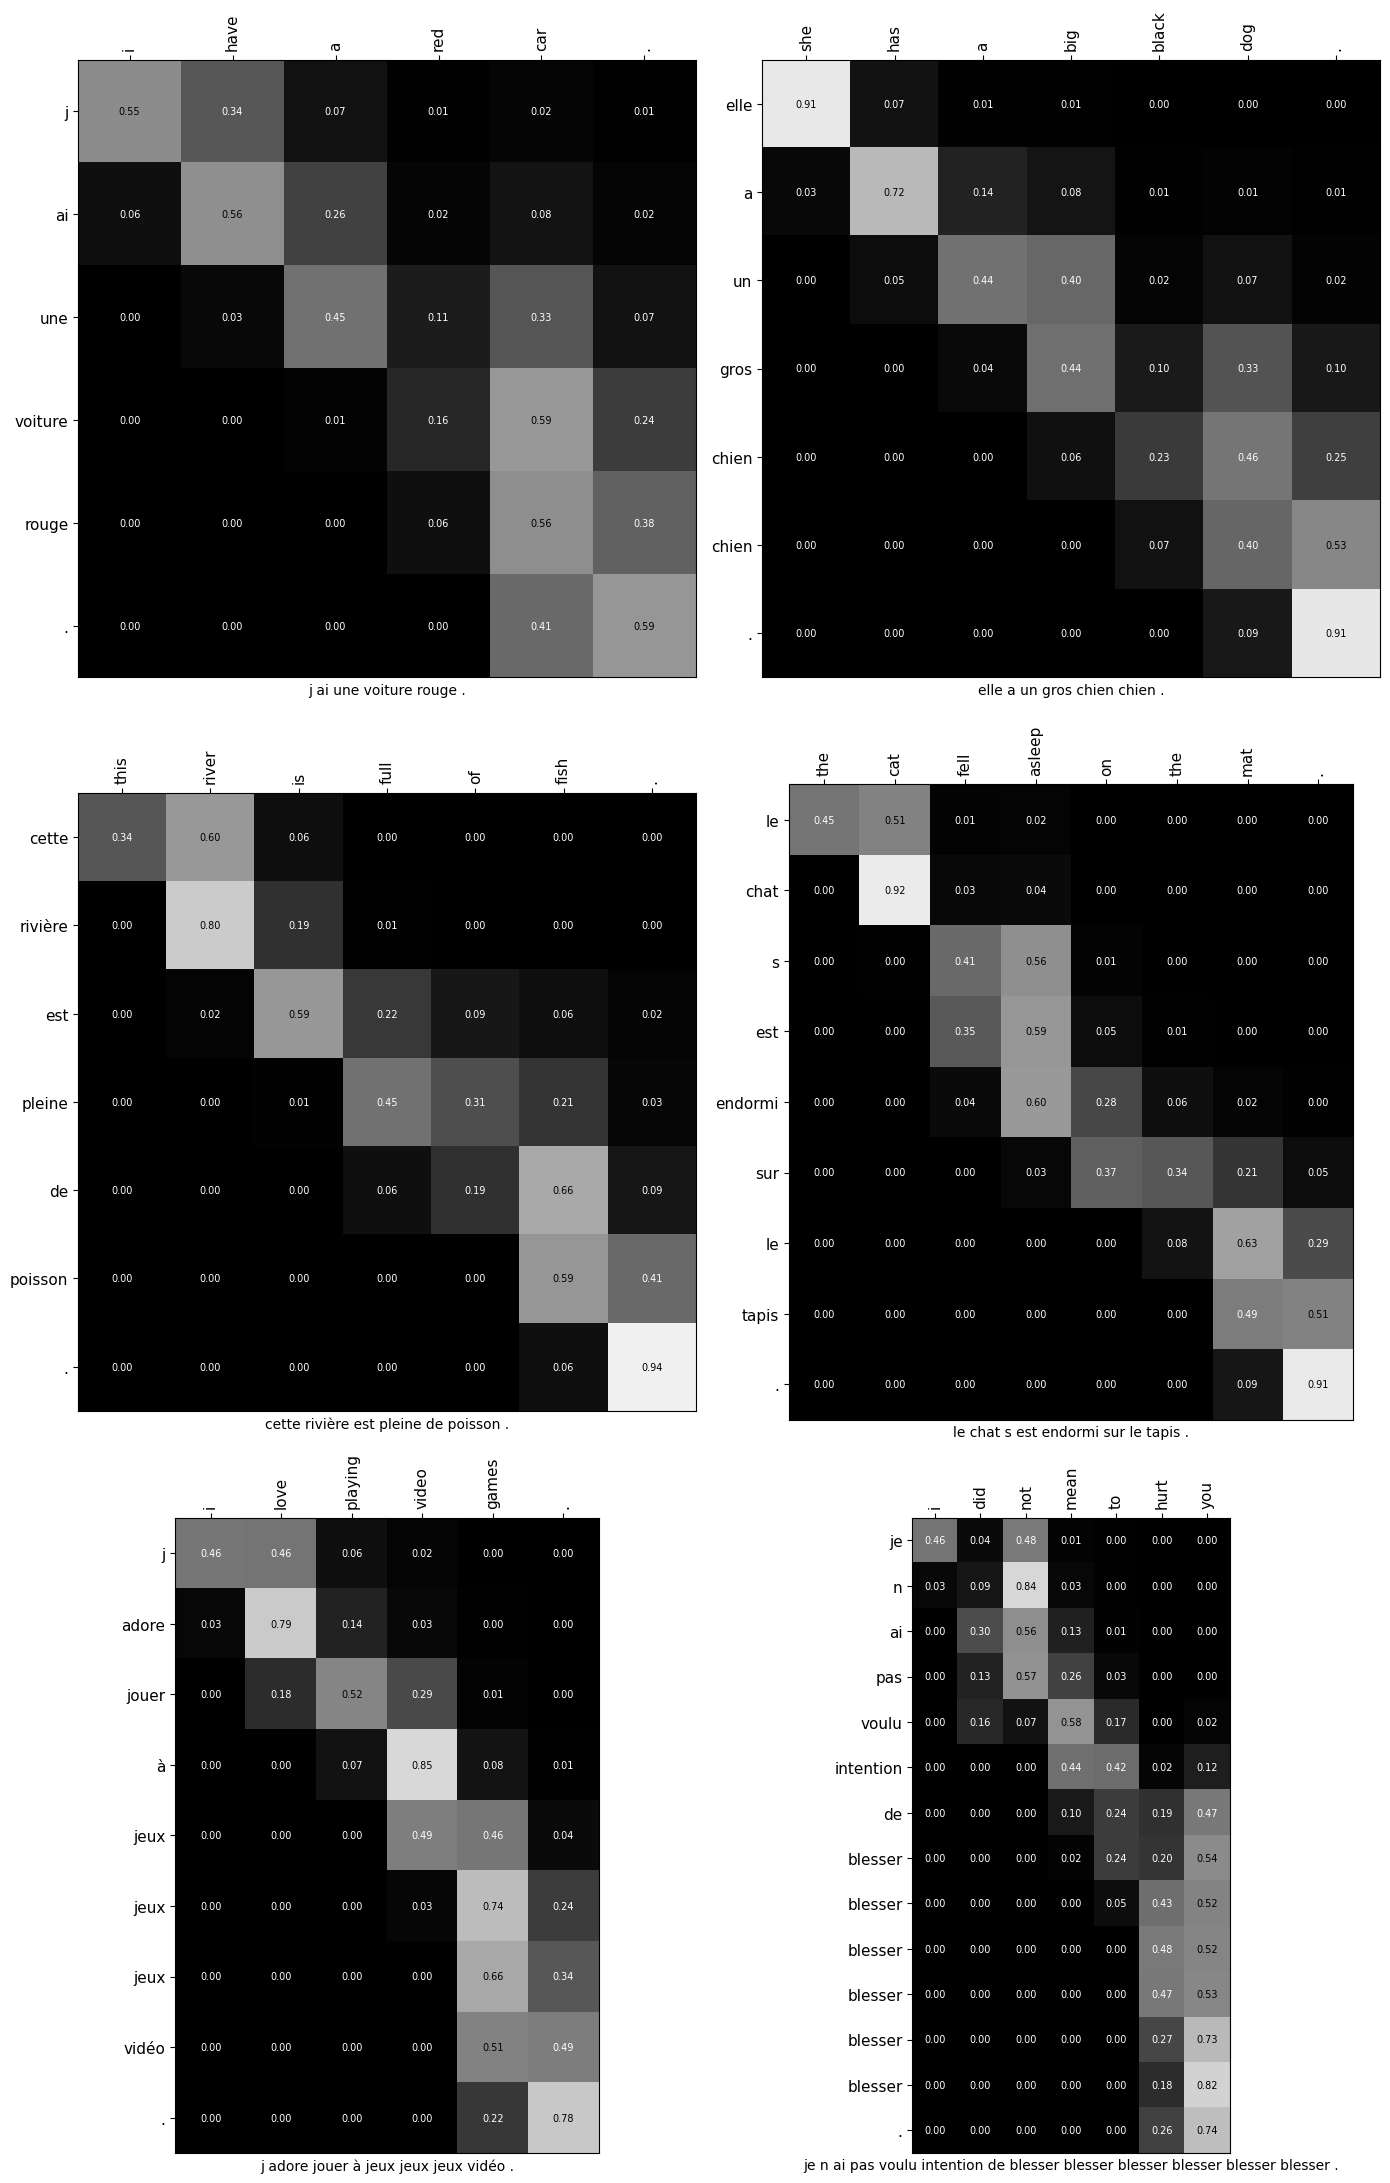

In [ ]:
def get_alignment(model, sentence):

    translation, weights = model.predict(sentence)
    source_tokens = word_tokenize(sentence.lower().replace("'", ' ').replace('-', ' '), model.source_language)
    target_tokens = translation.split(' ')
    A = np.array(weights)  # (T_y, T_x)
    cut = len(target_tokens)
    for t, tok in enumerate(target_tokens):
        if tok in ('<EOS>', '.', '!', '?'):
            cut = t + 1
            break #we stop when we find any possible end of sentence
    return source_tokens, target_tokens[:cut], A[:cut]


def plot_alignment(model, sentence, ax=None, annotate=True):
    src, tgt, A = get_alignment(model, sentence)
    if ax is None:
        _, ax = plt.subplots(figsize=(0.7 * len(src) + 1.5, 0.6 * len(tgt) + 1.5))
    ax.imshow(A, cmap='gray', vmin=0, vmax=1)
    ax.set_xticks(range(len(src)))
    ax.set_xticklabels(src, rotation=90, fontsize=11)
    ax.set_yticks(range(len(tgt)))
    ax.set_yticklabels(tgt, fontsize=11)
    ax.xaxis.tick_top()
    if annotate:
        for t in range(A.shape[0]):
            for j in range(A.shape[1]):
                ax.text(j, t, '%.2f' % A[t, j], ha='center', va='center', fontsize=7,
                        color='black' if A[t, j] > 0.5 else 'white')
    ax.set_xlabel(' '.join(tgt), fontsize=10)
    return ax


examples = ['I have a red car.',
            'She has a big black dog.',
            'This river is full of fish.',
            'The cat fell asleep on the mat.',
            'I love playing video games.',
            'I did not mean to hurt you']

fig, axes = plt.subplots(3, 2, figsize=(14, 22))
for ax, sentence in zip(axes.flatten(), examples):
    plot_alignment(model, sentence, ax=ax)
plt.tight_layout()
plt.show()

<b><h4><font color='green'>
<hr style="border:10px solid red"> </hr>
Answer 3: </font></h4></b>

Row $t$ is the generated target word, column $j$ is the source token, and white means $\alpha_{t,j}\approx1$. Note that our encoder is unidirectional, so $\bar h_j$ summarises $x_1,\dots,x_j$, unlike the bidirectional annotations of [Bahdanau et al., 2014].

First of all, we can observe a monotonic near-diagonal alignment, since English and French share SVO order: *rivière - river* (0.80), *est - is* (0.59), *chat - cat* (0.92), *adore - love* (0.79). The model learned these alignments with no alignment supervision. The adjective-noun inversion, however, is handled differently from what Bahdanau et al. report. For *voiture*, the model skips *red* and attends to *car* (0.59). *rouge* does not move back to *red* (0.06): it stays on *car* (0.56). We therefore do not get the crossing pattern of Bahdanau's *European Economic Area → zone économique européenne*. Because the encoder is unidirectional, $\bar h_{car}$ already encodes "red car", so the inversion is carried by the hidden states rather than by an explicit backward jump of attention. *video games → jeux vidéo* behaves the same way.

On the other hand, we can underline cases of phrasal verbs and negation. *s'*, *est* and *endormi* all spread their attention over *fell asleep*, so the phrasal verb is translated as a unit. Similarly, *n'* (0.84) and *pas* (0.57) both align to *not*, a one-to-many alignment that is discontinuous in French. Moreover, determiners look ahead to their noun: *cette* attends to *river* (0.60) and *le* to *cat* (0.51), which provides the evidence needed to choose the right gender.

Finally, we also observe failures. In "big black dog", *black* never gets more than 0.23 attention, so this low value causes that *noir* is never produced, and *chien* is repeated. For the final ".", attention concentrates on the source "." (0.91 in the dog sentence, 0.94 in the river one), and greedy decoding keeps producing "." from there, which is consistent with the endless dots discussed in Answer 2.

*Reference:* D. Bahdanau, K. Cho, Y. Bengio (2014). *Neural Machine Translation by Jointly Learning to Align and Translate*. [arXiv:1409.0473](https://arxiv.org/abs/1409.0473)

<hr style="border:10px solid red"> </hr>




<b><h4><font color='red'>
<hr style="border:10px solid red"> </hr>
Question 4 (5 points): </b><br>
What do you observe in the translations of the sentences below?
What properties of language models does that illustrate?
Read <a href='https://arxiv.org/abs/1802.05365'>[Peters et al., 2018]</a> and <a href='https://arxiv.org/abs/1810.04805'>[Devlin et al., 2018]</a>  to get some ideas.
<ul>
<b><h4><font color='red'>
<li>$\texttt{I did not mean to hurt you}$
<li>$\texttt{She is so mean}$
</ul>
<hr style="border:10px solid red"> </hr>
</font></h4>



In [ ]:
# Supporting probe for Answer 4: how contextual are the encoder states of "mean"?
def cos(a, b):
    return torch.nn.functional.cosine_similarity(a, b, dim=0).item()


probe = {'I did not mean to hurt you': 'mean', 'What do you mean ?': 'mean', 'I mean it': 'mean',
         'She is so mean': 'mean', 'He is a mean person': 'mean', 'Do not be mean to your sister': 'mean',
         'She is so cruel': 'cruel'}
states = {}
for s, w in probe.items():
    x = model.sourceNl_to_ints(s)
    hs = model.encoder(x.unsqueeze(1)).squeeze(1)                    # (seq, feat)
    states[s] = hs[word_tokenize(s.lower(), 'english').index(w)]
names = list(probe)
print('%-32s' % '', ''.join('%7d' % i for i in range(len(names))))
for i, a in enumerate(names):
    print('%d %-30s' % (i, a[:30]), ''.join('%7.2f' % cos(states[a], states[b]) for b in names))
# the input embedding (before any context is used) of "mean" in two different sentences
pos = lambda s, w: word_tokenize(s.lower(), 'english').index(w)
e_verb = model.encoder.embedding(model.sourceNl_to_ints(names[0])[pos(names[0], 'mean')])
e_adj = model.encoder.embedding(model.sourceNl_to_ints(names[3])[pos(names[3], 'mean')])
print('cosine of the input embeddings of "mean" in sentences 0 and 3: %.2f' % cos(e_verb, e_adj))

print() #Translation of the extra sentence
print('What do you mean ? ->', model.predict('What do you mean ?')[0])

                                       0      1      2      3      4      5      6
0 I did not mean to hurt you        1.00   0.82   0.89   0.86   0.79   0.90   0.14
1 What do you mean ?                0.82   1.00   0.82   0.81   0.73   0.85   0.05
2 I mean it                         0.89   0.82   1.00   0.83   0.80   0.83  -0.08
3 She is so mean                    0.86   0.81   0.83   1.00   0.92   0.93   0.20
4 He is a mean person               0.79   0.73   0.80   0.92   1.00   0.85   0.23
5 Do not be mean to your sister     0.90   0.85   0.83   0.93   0.85   1.00   0.21
6 She is so cruel                   0.14   0.05  -0.08   0.20   0.23   0.21   1.00
cosine of the input embeddings of "mean" in sentences 0 and 3: 1.00

What do you mean ? -> qu veux vous dire ? ? ? ? <EOS>


<b><h4><font color='green'>
<hr style="border:10px solid red"> </hr>
Answer 4: </font></h4></b>

| source | our model | sense of *mean* |
|---|---|---|
| I did not mean to hurt you | je n'ai pas voulu intention de blesser … | verb, "to intend" |
| She is so mean | elle est tellement méchant méchant | adjective, "unkind" |
| What do you mean? *(extra)* | qu' veux vous dire ? | verb, "to signify" |

Although these translations can also contain errors, due to repetition or to the wrong choice of gender for an adjective, we can observe that *mean* is correctly interpreted in each sentence. In fact, in the first one we see how the model blends two valid translations of *mean*.

The input embedding of *mean* is identical in all three sentences, since `nn.Embedding` is a lookup table. Therefore, the difference between the translations arises from the context: the encoder state $\bar h_j$ depends on the preceding words, and the decoder is a conditional language model in which, after *elle est tellement*, only an adjective fits. This illustrates what Peters et al. (2018) exploit with ELMo: in our model, hidden states are contextual word representations, so a word's meaning is a function of its sentence rather than of its type. ELMo shows that its top biLM layer alone reaches 69.0 F1 on word-sense disambiguation, close to dedicated systems.

Our own encoder is a much weaker contextualise. In the cell above, we can observe cosine similarities of $\bar h_{mean}$, that prove this fact:

| comparison | cosine |
|---|---|
| *mean* (adj.) vs. *mean* (adj.) | 0.90 |
| *mean* (verb) vs. *mean* (adj.) | 0.82 |
| *mean* vs. *cruel* in "She is so ___" | 0.20 |

The states group only a little bit by sense and depend mostly on the word itself, so much of the disambiguation is left to the decoder. The encoder also reads the sentence from left to right, so the state at *mean* cannot depend on the words that come after it. For example, taking "the mean of the data" (*moyenne*) and "the mean man" (*méchant*), the encoder has only seen "the mean" at that point, so the state is the same. It cannot know whether *mean* is a noun or an adjective. The information needed to decide can only reach the decoder through the later encoder states, so the translation will probably be less reliable. ELMo tackles this by joining a left-to-right and a right-to-left language model. However, the two directions never interact: each one sees only its own side, and their states are simply put side by side, so the combination is shallow. BERT [Devlin et al., 2019] works differently. Thanks to its masked language modelling objective, every layer uses the words on both sides together, which gives deep bidirectional representations.

*References:*
- M. E. Peters et al. (2018). *Deep contextualized word representations*. NAACL. [arXiv:1802.05365](https://arxiv.org/abs/1802.05365)
- J. Devlin, M.-W. Chang, K. Lee, K. Toutanova (2019). *BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding*. NAACL. [arXiv:1810.04805](https://arxiv.org/abs/1810.04805)

<hr style="border:10px solid red"> </hr>

### <b>6. Appendix:</b>
<h4><b>6.1. GRU unit:</b></h4>
<p style="text-align: justify;">
As shown in Fig. 3, the GRU unit <a href='https://arxiv.org/abs/1406.1078'>[Cho et al., 2014]</a> is a simple RNN unit with two gates (reset and update):

\begin{equation}
\text{reset gate:}~~r_{t} = \sigma \big(U_{r}x_{t} + W_{r}h_{t-1} + b_r\big)
\end{equation}

\begin{equation}
\text{update gate:}~~z_{t} = \sigma \big(U_{z}x_{t} + W_{z}h_{t-1} + b_z\big)
\end{equation}

The candidate hidden state is computed as:

\begin{equation}
\hat{h}_{t} = \mathrm{tanh} \big(U_{h}x_{t} + W_{h} (r_t \circ h_{t-1}) + b_h\big)
\end{equation}

<center>
<img width='500px' src='https://1drv.ms/i/c/ae69638675180117/UQQXARh1hmNpIICuuYQBAAAAAEpvFJzwgjB2a3Y?width=703&height=489' />
<br>
<b>Figure 3:</b> GRU unit. Taken from <a href='http://colah.github.io/posts/2015-08-Understanding-LSTMs/'>Chris Olah's blog</a>.<br>
</center>

The reset gate determines how much of the information from the previous time steps (stored in $h_{t-1}$) should be discarded.
The new hidden state is finally obtained by linearly interpolating between the previous hidden state and the candidate one:

\begin{equation}
h_{t} = (1-z_t) \circ {h}_{t-1} + z_t \circ \hat{h}_{t}
\end{equation}